# Sunday Project | Sales Data Quality and CSV Operations

## Part A | Data Quality & Basic Insights
### A1. Load and inspect the raw sales file

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

raw_sales = pd.read_csv("sales_raw.csv")

print(raw_sales.head())    #displaying first 5 rows
print("\nShape:", raw_sales.shape)   #displaying shape i.e rows & columns
print("Columns:", raw_sales.columns.tolist())  #showing the columns names
print("\nData types:")
print(raw_sales.dtypes.to_string())        #data types of each column
print("\nMissing values:")
print(raw_sales.isna().sum().to_string())    #checking missing values
print("\nDuplicate rows:", raw_sales.duplicated().sum())    #checking duplicate rows


   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250

Shape: (21, 6)
Columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data types:
transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object

Missing values:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1

Duplicate rows: 1


### A2. Clean the sales records

In [4]:
sales = raw_sales.copy()

for column in ["region", "category"]:
    sales[column] = sales[column].str.strip().str.title().replace("", pd.NA)

sales["region"] = sales["region"].fillna("Unknown")
sales = sales.drop_duplicates().copy()

sales["sale_date"] = pd.to_datetime(sales["sale_date"], format="%m/%d/%Y", errors="coerce")
sales["quantity"] = pd.to_numeric(sales["quantity"], errors="coerce")
sales["unit_price"] = pd.to_numeric(sales["unit_price"], errors="coerce")

# Check the unusual Stationery price against the other prices.
stationery = sales["category"].eq("Stationery")
print("Stationery prices:", sales.loc[stationery, "unit_price"].dropna().tolist())

unconfirmed_price = sales["transaction_id"].eq(1016) & sales["unit_price"].eq(10000)
valid_sales = sales["sale_date"].notna() & sales["quantity"].gt(0) & ~unconfirmed_price
print("Rows excluded after removing duplicates:", sales.loc[~valid_sales, "transaction_id"].tolist())

sales = sales.loc[valid_sales].copy()
sales["quantity"] = sales["quantity"].astype(int)
sales["unit_price"] = sales["unit_price"].where(sales["unit_price"].gt(0))

# Use prices from the same category to fill the gaps.
needs_price = sales["unit_price"].isna()
category_median = sales.groupby("category")["unit_price"].transform("median")
sales["unit_price"] = sales["unit_price"].fillna(category_median)

print("\nTransactions with filled prices:")
print(sales.loc[needs_price, ["transaction_id", "category", "unit_price"]].to_string(index=False))
print("\nRows before cleaning:", len(raw_sales))
print("Rows after cleaning:", len(sales))


Stationery prices: [50.0, 60.0, 10000.0, 40.0]
Rows excluded after removing duplicates: [1006, 1013, 1014, 1016]

Transactions with filled prices:
 transaction_id   category  unit_price
           1010 Stationery        50.0
           1011       Food       105.0

Rows before cleaning: 21
Rows after cleaning: 16


### A3. Calculate revenue and plot the totals

In [5]:
sales["revenue"] = (sales["quantity"] * sales["unit_price"]).round(2)   #revenue column: quantity × unit_price

region_revenue = sales.groupby("region")["revenue"].sum().sort_values(ascending=False)  #summarize revenue by region
category_revenue = sales.groupby("category")["revenue"].sum().sort_values(ascending=False)  #summarize revenue by category

print("Revenue by region")
print(region_revenue.to_string())
print("\nRevenue by category")
print(category_revenue.to_string())


Revenue by region
region
North      1470.0
South      1135.0
East        950.0
West        530.0
Unknown     400.0

Revenue by category
category
Food          2155.0
Books         1770.0
Stationery     560.0


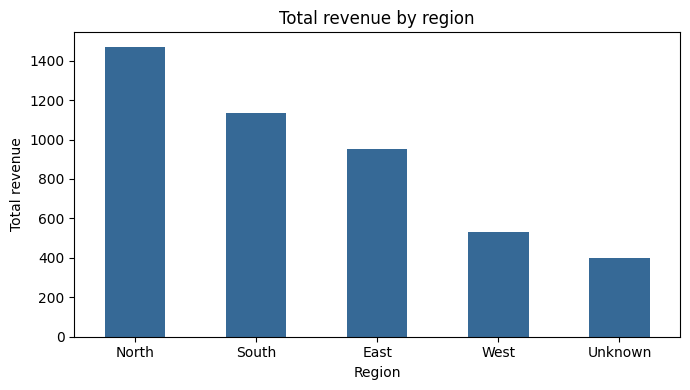

In [6]:
region_revenue.plot(kind="bar", color="#366996", rot=0, figsize=(7, 4))
plt.title("Total revenue by region")
plt.xlabel("Region")
plt.ylabel("Total revenue")
plt.tight_layout()
plt.show()


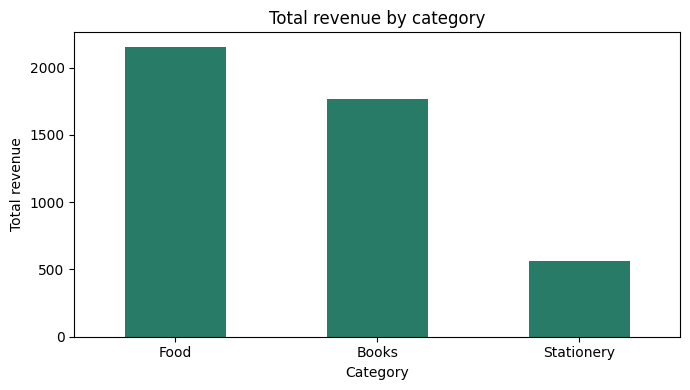

In [7]:
category_revenue.plot(kind="bar", color="#287b66", rot=0, figsize=(7, 4))
plt.title("Total revenue by category")
plt.xlabel("Category")
plt.ylabel("Total revenue")
plt.tight_layout()
plt.show()


**Two findings from the cleaned data**

1. **North** had the highest recorded revenue at **1,470.00**. That was **335.00** more than South, the next highest region.
2. **Food** brought in **2,155.00**, about **48.0%** of total cleaned revenue. It was the highest-revenue category.

### A4. Save the cleaned sales file

In [8]:
sales.to_csv("cleaned_sales.csv", index=False)
print("Saved cleaned_sales.csv")


Saved cleaned_sales.csv


## Part B | CSV File Handling & Manipulation
### B1. Read the cleaned file and add 5% tax

In [9]:
updated_sales = pd.read_csv("cleaned_sales.csv")           #loaded new cleaned dataset
updated_sales["tax_amount"] = (updated_sales["revenue"] * 0.05).round(2)        # tax amount equal to 5% of revenue

print(updated_sales.head())


   transaction_id   sale_date region    category  quantity  unit_price  \
0            1001  2026-10-01  North        Food         2       120.0   
1            1002  2026-10-01  South       Books         1       250.0   
2            1003  2026-10-02  North        Food         3       110.0   
3            1004  2026-10-02   East  Stationery         4        50.0   
4            1005  2026-10-03  South       Books         2       250.0   

   revenue  tax_amount  
0    240.0        12.0  
1    250.0        12.5  
2    330.0        16.5  
3    200.0        10.0  
4    500.0        25.0  


### B2. Raise Books prices, remove one sale, and drop a temporary column




In [10]:
books = updated_sales["category"].eq("Books")
#increasing unit price by 10%
updated_sales.loc[books, "unit_price"] = (updated_sales.loc[books, "unit_price"] * 1.10).round(2)

# Update both amounts after changing the price.
updated_sales["revenue"] = (updated_sales["quantity"] * updated_sales["unit_price"]).round(2)
updated_sales["tax_amount"] = (updated_sales["revenue"] * 0.05).round(2)

#remove row using an existing transaction Id
sale_to_remove = 1019
updated_sales = updated_sales.loc[updated_sales["transaction_id"].ne(sale_to_remove)].copy()

#creating temporary review_status column
updated_sales["review_status"] = "Ready to check"
updated_sales = updated_sales.drop(columns=["review_status"])

print("Removed transaction:", sale_to_remove)
print("Rows after removal:", len(updated_sales))


Removed transaction: 1019
Rows after removal: 15


### B3. Save and verify the updated CSV

In [11]:
updated_sales.to_csv("sales_updated.csv", index=False)
saved_sales = pd.read_csv("sales_updated.csv")

print(saved_sales.head().to_string(index=False))
print("\nFinal columns:", saved_sales.columns.tolist())


 transaction_id  sale_date region   category  quantity  unit_price  revenue  tax_amount
           1001 2026-10-01  North       Food         2       120.0    240.0       12.00
           1002 2026-10-01  South      Books         1       275.0    275.0       13.75
           1003 2026-10-02  North       Food         3       110.0    330.0       16.50
           1004 2026-10-02   East Stationery         4        50.0    200.0       10.00
           1005 2026-10-03  South      Books         2       275.0    550.0       27.50

Final columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
